In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets,transforms
from torchvision.utils import make_grid

In [2]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
%matplotlib inline


In [3]:
#convert image file into tensor at 4 dimenssion
## Hight,width,color channels
transforms=transforms.ToTensor()

In [4]:
## Train data
train_data=datasets.MNIST(root='/cnn_data',train=True,download=True,transform=transforms)

In [5]:
## test data
test_data=datasets.MNIST(root='/cnn_data',train=False,download=True,transform=transforms)

In [6]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: /cnn_data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [7]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: /cnn_data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [8]:
## create a small batch size for images

train_loader=DataLoader(train_data,batch_size=10,shuffle=True)
test_loader=DataLoader(test_data,batch_size=10,shuffle=False)

In [9]:
##define CNN
conv1=nn.Conv2d(1,6,3,1)
conv2=nn.Conv2d(6,16,3,1)

In [10]:
## grab 1 MINST record

for i,(X_train,y_train) in enumerate(train_data):
    break

In [11]:
X_train.shape

torch.Size([1, 28, 28])

In [12]:
x=X_train.view(1,1,28,28)

In [13]:
## perform our first convolution
x=F.relu(conv1(x))# Rectifirfd linear unit for our activation fnction

In [14]:
x

tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

         [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

         [[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0

In [15]:
x.shape

torch.Size([1, 6, 26, 26])

In [16]:
# oas through the pooling layer
x=F.max_pool2d(x,2,2)## kernal of 2 and stride of 2

In [17]:
x.shape  ## 26/2=13

torch.Size([1, 6, 13, 13])

In [18]:
##do our second convolution layer 
x=F.relu(conv2(x))

In [19]:
x.shape ## again pixel decreases

torch.Size([1, 16, 11, 11])

In [20]:
x=F.max_pool2d(x,2,2)

In [21]:
x.shape ## 11/2=5.5=> 5

torch.Size([1, 16, 5, 5])

In [22]:
## building model for cnn

## model class

class ConvolutionalNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(1,6,3,1)
        self.conv2=nn.Conv2d(6,16,3,1)
        ## fully connected layer

        self.fc1=nn.Linear(5*5*16,120)
        self.fc2=nn.Linear(120,84)
        self.fc3=nn.Linear(84,10)

    def forward(self,X):
        X=F.relu(self.conv1(X))
        X=F.max_pool2d(X,2,2)
        #second pass
        X=F.relu(self.conv2(X))
        X=F.max_pool2d(X,2,2)

        ## Re-view to flatte it out
        X=X.view(-1,16*5*5)


        ## fully connected layers
        X=F.relu(self.fc1(X))
        X=F.relu(self.fc2(X))
        X=self.fc3(X)
        return F.log_softmax(X,dim=1)



In [23]:
## create an intance of model

torch.manual_seed(41)
model=ConvolutionalNetwork()
model

ConvolutionalNetwork(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [24]:
#loss fuction optimizer
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.001)

In [25]:

import time
start_time=time.time()


## create variables to track things
epochs=5
train_losses=[]
test_losses=[]
train_correct=[]
test_correct=[]




## for loop for epoches

for i in range(epochs):
    trn_corr=0
    tst_corr=0



    ## train
    model.train()

    for b,(X_train,y_train) in enumerate(train_loader):
        b+=1 ## start batch at 1

        y_pred=model(X_train) ##get the prediction value from the training set.not falttened 2d

        loss=criterion(y_pred,y_train) # compare the predictions with correct answer

        predicted=torch.max(y_pred.data,1)[1] ## add up the number of correct predictionsIndex off the first point

        batch_corr=(predicted==y_train).sum() ## how many of we got correct from this batch.True =1, false=0 and we sum those up

        trn_corr+=batch_corr ## keep track as we go along in tracking





        #update our parameters
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()





        ## print out some results

        if b%600==0:
            print(f"EPoches: {i+1} Batch: {b}  Loss: {loss.item()}")



    train_losses.append(loss.item())
    train_correct.append(trn_corr.item())



    ##Test
    model.eval()

    with torch.no_grad(): ## no gradiant so we dont update our weights and bais with test data

        for b,(X_test,y_test) in enumerate(test_loader):

            y_val=model(X_test)

            predicted=torch.max(y_val.data,1)[1] ## Add up correct predictions

            tst_corr+=(predicted==y_test).sum() ## T=1 F=0 and sum away

            loss=criterion(y_val,y_test)


    test_losses.append(loss.item())
    test_correct.append(tst_corr.item())


    print(f"Epoch: {i+1} | Train Correct: {trn_corr.item()} | Test Correct: {tst_corr.item()}")


current_time=time.time()
total=current_time-start_time

print(f"Training took:{total/60:.2f} minuites")


EPoches: 1 Batch: 600  Loss: 0.16236233711242676
EPoches: 1 Batch: 1200  Loss: 0.16415365040302277
EPoches: 1 Batch: 1800  Loss: 0.5489689111709595
EPoches: 1 Batch: 2400  Loss: 0.13124826550483704
EPoches: 1 Batch: 3000  Loss: 0.005137370899319649
EPoches: 1 Batch: 3600  Loss: 0.5259817242622375
EPoches: 1 Batch: 4200  Loss: 0.00602962588891387
EPoches: 1 Batch: 4800  Loss: 0.0012086734641343355
EPoches: 1 Batch: 5400  Loss: 0.090482197701931
EPoches: 1 Batch: 6000  Loss: 0.0003286387654952705
Epoch: 1 | Train Correct: 56254 | Test Correct: 9757
EPoches: 2 Batch: 600  Loss: 0.0018097307765856385
EPoches: 2 Batch: 1200  Loss: 0.26618659496307373
EPoches: 2 Batch: 1800  Loss: 0.0030415812507271767
EPoches: 2 Batch: 2400  Loss: 0.002535218372941017
EPoches: 2 Batch: 3000  Loss: 0.027494752779603004
EPoches: 2 Batch: 3600  Loss: 0.4434588849544525
EPoches: 2 Batch: 4200  Loss: 0.04717915505170822
EPoches: 2 Batch: 4800  Loss: 0.0005920641124248505
EPoches: 2 Batch: 5400  Loss: 0.000329558

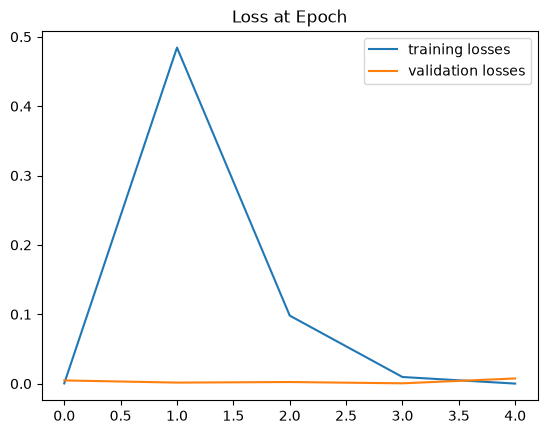

In [26]:
#graf the loss at epoch
plt.plot(train_losses,label="training losses")
plt.plot(test_losses,label="validation losses")
plt.title("Loss at Epoch")
plt.legend()

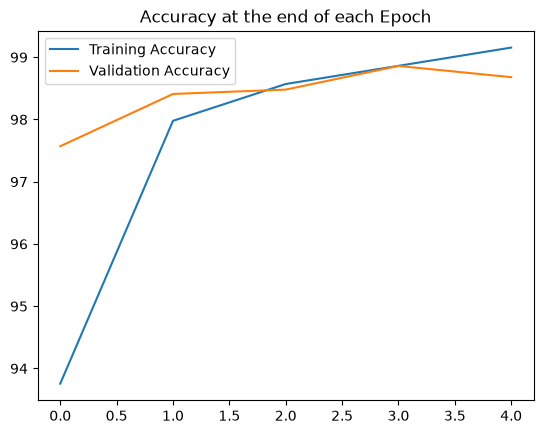

In [27]:

# graph the accuracy at the end of each epoch
plt.plot([t/600 for t in train_correct], label="Training Accuracy")
plt.plot([t/100 for t in test_correct], label="Validation Accuracy")
plt.title("Accuracy at the end of each Epoch")
plt.legend()

In [28]:

test_load_everything = DataLoader(test_data, batch_size=10000, shuffle=False)

In [29]:
with torch.no_grad():
  correct = 0
  for X_test, y_test in test_load_everything:
    y_val = model(X_test)
    predicted = torch.max(y_val, 1)[1]
    correct += (predicted == y_test).sum()

In [31]:
# Did for correct
correct.item()/len(test_data)*100

98.68

In [32]:

# Grab an image
test_data[1978] # Tensor with an image in it...at end, it shows the label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 